# 3. Beam-state initialization test — Python

This notebook tests **only** `BeamState.initialize`, corresponding to `KLJCmainsv22.m` lines 136–149 and 157–159. The reference beam and longitudinal grid are calculated first, independently in each language.

Follow the same workflow as tests 1 and 2:

1. Edit the inputs, then **Restart Kernel and Run All** here.
2. Run all sections of `beam_state_test.mlx` (or its readable `.m` source).
3. Run `compare_results.ipynb` to compare the saved outputs.

No cavity field, circuit solution, plasma frequency, space charge, electron trajectory, or nonlinear update is computed. The flat longitudinal profiles below are **initial guesses**, not propagated beam solutions. See [the test README](../README.md).


In [1]:
# Import necessary libraries and modules

from pathlib import Path
import sys

import numpy as np
import matplotlib.pyplot as plt
from scipy.io import savemat
from IPython.display import Markdown, display


In [2]:
# Import custom modules and classes to be tested

current_directory = Path.cwd().resolve()
project_directory = next(
    path
    for parent in (current_directory, *current_directory.parents)
    for path in (parent, parent / "pyKlyC")
    if (path / "src" / "solver" / "grid.py").exists()
)
test_directory = project_directory / "test" / "3.beam_state_test"
sys.path.insert(0, str(project_directory / "src"))

from constants import c, etom, mu01
from model.beam import BeamParameters
from model.cavity import CavityParameters
from model.settings import NumericalSettings
from model.tube import TubeParameters
from solver.reference import ReferenceParameters
from solver.grid import GridParameters
from solver.beam_state import BeamState


In [3]:
# Set global options for numpy and matplotlib

np.set_printoptions(precision=6, linewidth=140)
# Apply the same dashed gray grid to every subplot.
# "line" places the grid above shaded regions, but below plotted lines.
plt.rcParams.update({
    "figure.dpi": 110,
    "font.size": 10,
    "axes.grid": True,
    "axes.axisbelow": "line",
    "grid.color": "gray",
    "grid.linestyle": "--",
    "grid.linewidth": 0.7,
    "grid.alpha": 0.45,
})

# Display options for Jupyter Notebook Tables

def show_table(rows):
    text = "| Variable | Value | Units | Meaning |\n"
    text += "|---|---|---|---|\n"
    for name, value, units, meaning in rows:
        if isinstance(value, np.ndarray):
            value = np.array2string(value, precision=5, max_line_width=1000)
        elif isinstance(value, (float, np.floating)):
            value = f"{value:.8g}"
        text += f"| `{name}` | {value} | {units} | {meaning} |\n"
    display(Markdown(text))


## 1. Editable inputs

The default `uniform` case uses the same 180 kV, −16 A beam and 1 GHz operating frequency as the previous tests.

Choose one preset using `case_name`:

- `uniform`: all samples active, constant voltage/current, `tn1 = t0`. RF harmonics should be zero to roundoff.
- `modulated`: prescribed current and voltage modulation, with `tn1 = t0 + 0.35`. This exercises nonzero complex harmonics and the velocity weighting in `QQ`.
- `partial_beam`: the same prescribed modulation, but only samples with `t0 < pi` are active. This checks `Y0`; the normalization still uses **Nt**, not the number of active samples.

The latter two cases are synthetic verification inputs, not solutions from the manual or a beam-dynamics calculation. Lengths are in mm, frequencies in GHz, voltages in kV, and currents in A. `Nt` samples one RF period; `Nz` controls spatial intervals per **electronic** wavelength.


In [4]:
case_name = "uniform"  # "uniform", "modulated", or "partial_beam"

# Beam and emission samples
Nbeam = 1
rm1 = 0.0
rm2 = 6.0
rc = 10.0
Nt = 128
t0 = 2.0 * np.pi * np.arange(Nt) / Nt
tn1 = t0.copy()
Y0 = np.arange(Nt)
Ut = np.full(Nt, 180.0)
Izt = np.full(Nt, -16.0)

# Prescribed test inputs: no electron trajectories are calculated.
if case_name in ("modulated", "partial_beam"):
    Izt = -16.0 * (1.0 + 0.20 * np.cos(t0 + 0.40) + 0.10 * np.sin(2.0 * t0 - 0.20))
    Ut = 180.0 * (1.0 + 0.03 * np.sin(t0 - 0.30))
    tn1 = t0 + 0.35
    if case_name == "partial_beam":
        Y0 = np.flatnonzero(t0 < np.pi)
elif case_name != "uniform":
    raise ValueError("Choose uniform, modulated, or partial_beam.")

# Cavity centers and RF parameters (no RF fields are calculated)
Nc = 5
f = 1.0
f0 = np.array([1.000, 1.006, 1.016, 1.030, 1.000])
zshift = np.array([0.0, 480.0, 1630.0, 2400.0, 2730.0])
type = np.array([0, 1, 1, 1, -1])
nh = np.ones(Nc, dtype=int)
Qext = np.array([334.0, 95000.0, 95000.0, 95000.0, 50.0])
Qin = np.array([16428.0, 19768.0, 19816.0, 16970.0, 14787.0])
Pin = np.array([60.0, 0.0, 0.0, 0.0, 0.0])
gaman = np.zeros(Nc, dtype=complex)
Lsb = np.pi * np.ones(Nc)
kai = np.zeros((Nc, Nc), dtype=complex)
cavityname = " ".join(f"guide_cavity_{k + 1}" for k in range(Nc))

# Longitudinal domain and constant-radius tunnel
z0 = -100.0
L = 3000.0
rcv = np.array([
    [z0, z0 + L],
    [1.0, 1.0],
])

# Numerical parameters
Nz = 256
Ns = 8
factorregion = 10.0
Nlimit = 100
Ntimes = 10
Rlimit = 1.0e-4
iterfactor = 0.5


## 2. Initialize the Python objects

`ReferenceParameters` computes `Iz0`, `U0`, the reference speed `s`, and `vn1 = v_reference / v_sample`. `GridParameters` creates the spatial axis. Then `BeamState.initialize` fills all longitudinal rows with the entrance harmonics.

Cavity parameters are required by the grid API; no cavity-field class or circuit solver is called.


In [5]:
beam = BeamParameters(
    Nbeam=Nbeam, rm1=rm1, rm2=rm2, rc=rc,
    xb=0.0, yb=0.0, xd=0.0, yd=0.0,
    Nt=Nt, t0=t0, Ut=Ut, Izt=Izt, tn1=tn1, Y0=Y0,
)
cavities = CavityParameters(
    type=type, nh=nh, f0=f0, Qext=Qext, Qin=Qin,
    zshift=zshift, Pin=Pin, gaman=gaman, Lsb=Lsb,
    cavityname=cavityname, kai=kai,
)
tube = TubeParameters(z0=z0, L=L, rcv=rcv)
numerical = NumericalSettings(
    f=f, Nc=Nc, Ns=Ns, Nz=Nz, Nlimit=Nlimit,
    Ntimes=Ntimes, Rlimit=Rlimit, iterfactor=iterfactor,
    evolutionmethod=np.array([0.005, 2.0]),
    upstream_discard_distance_mm=0.0,
    efficiency_end_offset_mm=3.0 * rc,
)

cavities.validate(Nc)

reference = ReferenceParameters.calculate_reference_parameters(beam)
grid = GridParameters.calculate(
    numerical, cavities, tube, beam, reference, factorregion
)

beam_state = BeamState.initialize(numerical, beam, grid, reference)


In [6]:
show_table([
    ("case_name", case_name, "-", "Selected prescribed beam input"),
    ("Nt", Nt, "samples", "Samples per full RF period, including inactive ones"),
    ("len(Y0)", len(Y0), "samples", "Active samples used in the sums"),
    ("Ns", Ns, "harmonics", "Positive harmonics; DC is stored separately"),
    ("Iz0", reference.Iz0, "A", "Signed mean current over a full period"),
    ("I0", reference.I0, "A", "Magnitude of the reference current"),
    ("U0", reference.U0, "kV", "Current-weighted mean emission voltage"),
    ("s", reference.s, "1", "Reference speed divided by c"),
    ("gama", reference.gama, "1", "Reference Lorentz factor"),
    ("len(z)", len(grid.z), "nodes", "Rows of every initialized beam array"),
    ("Iz.shape", str(beam_state.Iz.shape), "-", "Rows: nodes; columns: harmonics 1..Ns"),
    ("QQ.shape", str(beam_state.QQ.shape), "-", "Same ordering as Iz"),
])


| Variable | Value | Units | Meaning |
|---|---|---|---|
| `case_name` | uniform | - | Selected prescribed beam input |
| `Nt` | 128 | samples | Samples per full RF period, including inactive ones |
| `len(Y0)` | 128 | samples | Active samples used in the sums |
| `Ns` | 8 | harmonics | Positive harmonics; DC is stored separately |
| `Iz0` | -16 | A | Signed mean current over a full period |
| `I0` | 16 | A | Magnitude of the reference current |
| `U0` | 180 | kV | Current-weighted mean emission voltage |
| `s` | 0.67314584 | 1 | Reference speed divided by c |
| `gama` | 1.3522472 | 1 | Reference Lorentz factor |
| `len(z)` | 3806 | nodes | Rows of every initialized beam array |
| `Iz.shape` | (3806, 8) | - | Rows: nodes; columns: harmonics 1..Ns |
| `QQ.shape` | (3806, 8) | - | Same ordering as Iz |


## 3. Inspect the prescribed entrance samples

The gray lines include inactive samples; only marked active samples contribute to initialization. `t0` labels departure phase, while `tn1` is the entrance phase used in the complex exponentials. Both are normalized times (radians), not seconds.

`vn1` is zero for inactive samples. For active samples, larger `vn1` means a slower electron and a larger charge-density weight for the same current.


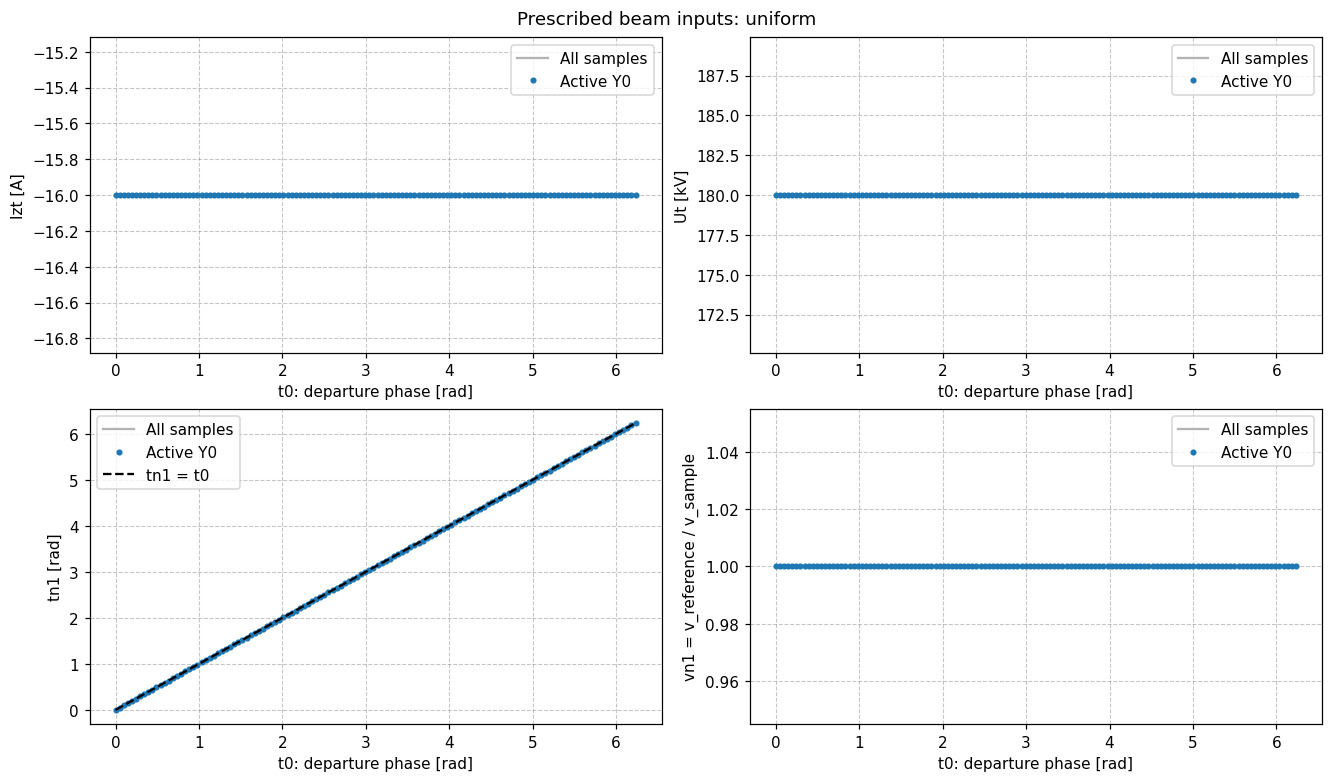

In [7]:
fig, axes = plt.subplots(2, 2, figsize=(12, 7), layout="constrained")
for ax, values, label in (
    (axes[0, 0], beam.Izt, "Izt [A]"),
    (axes[0, 1], beam.Ut, "Ut [kV]"),
    (axes[1, 0], beam.tn1, "tn1 [rad]"),
    (axes[1, 1], reference.vn1, "vn1 = v_reference / v_sample"),
):
    ax.plot(beam.t0, values, color="0.7", label="All samples")
    ax.plot(beam.t0[beam.Y0], values[beam.Y0], ".", label="Active Y0")
    ax.set(xlabel="t0: departure phase [rad]", ylabel=label)
    ax.legend()
axes[1, 0].plot(beam.t0, beam.t0, "--", color="black", label="tn1 = t0")
axes[1, 0].legend()
fig.suptitle(f"Prescribed beam inputs: {case_name}")
plt.show()


## 4. Current and charge harmonics — including harmonic zero

For active samples \(j\in Y_0\), write \(a_j=Izt_j/Iz0\). The MATLAB convention is

\[
IzDC=\frac{1}{Nt}\sum_j a_j,\qquad
Iz_k=\frac{2i}{Nt}\sum_j a_j e^{-ik\,tn1_j},
\]
\[
QQDC=\frac{1}{Nt}\sum_j a_j\,vn1_j,\qquad
QQ_k=\frac{2i}{Nt}\sum_j a_j\,vn1_j e^{-ik\,tn1_j}.
\]

All these quantities are **dimensionless**. The charge coefficients include inverse-velocity weighting. `IzDC = 1` by the definition of `Iz0`; `QQDC` need not equal one when sample velocities differ.

For display only, column zero below contains `IzDC` or `QQDC`; the stored `Iz` and `QQ` matrices still have exactly `Ns` columns, starting at harmonic 1. Real and imaginary parts are shown because magnitudes alone hide phase/sign errors.


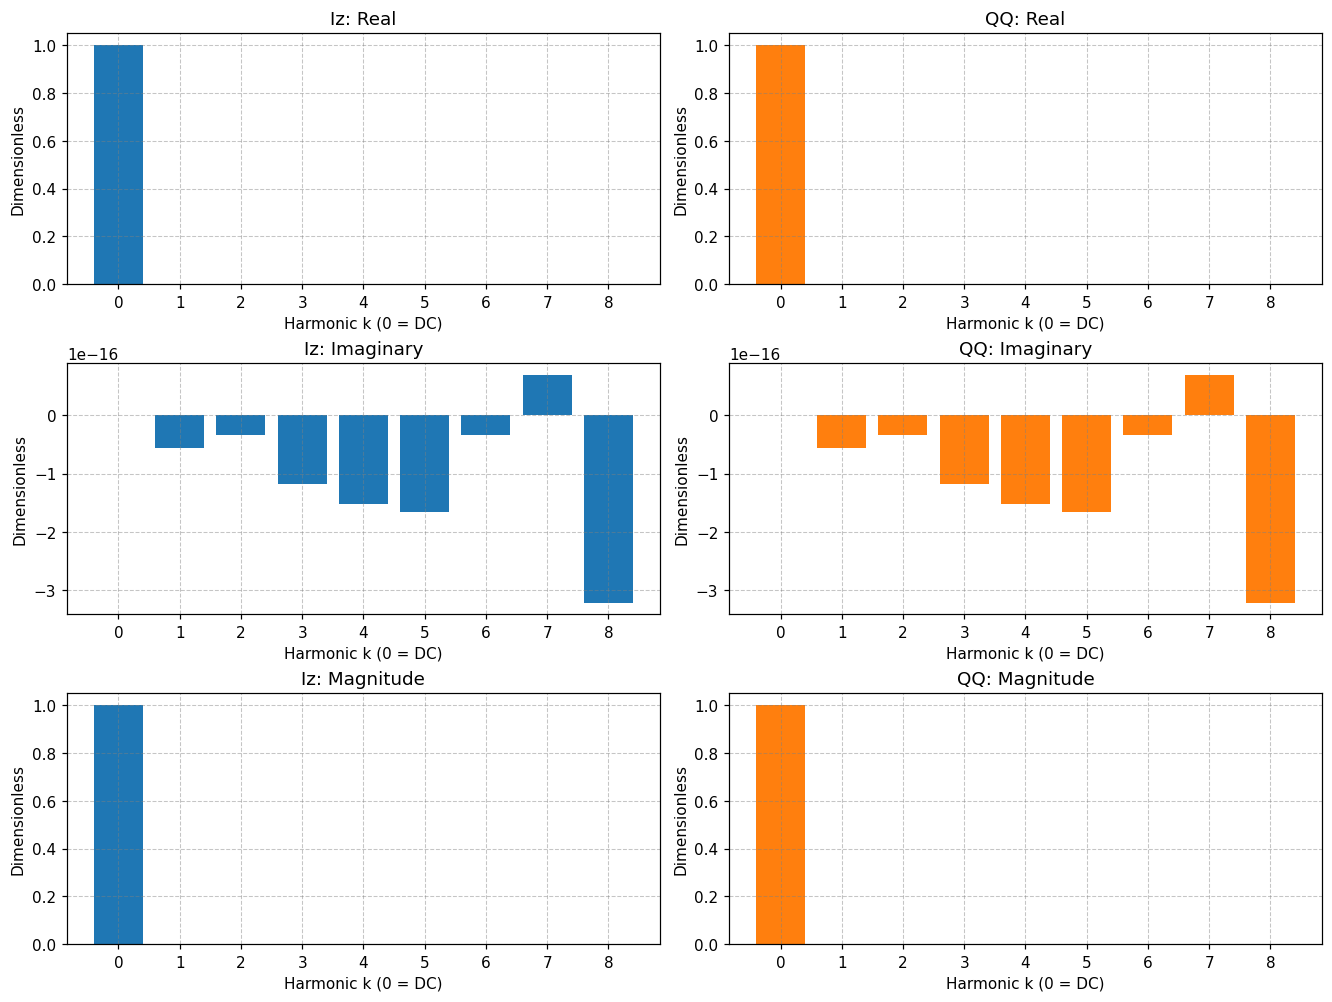

| Harmonic | Iz (complex) | QQ (complex) |
|---|---|---|
| 0 | 1+0j | 1+0j |
| 1 | 1.110223e-16-5.5511151e-17j | 1.110223e-16-5.5511151e-17j |
| 2 | 2.1250363e-17-3.469447e-17j | 2.1250363e-17-3.469447e-17j |
| 3 | -0-1.179612e-16j | -0-1.179612e-16j |
| 4 | 4.3368087e-17-1.5265567e-16j | 4.3368087e-17-1.5265567e-16j |
| 5 | 5.5511151e-17-1.6653345e-16j | 5.5511151e-17-1.6653345e-16j |
| 6 | -6.5919492e-17-3.3827108e-17j | -6.5919492e-17-3.3827108e-17j |
| 7 | 4.1633363e-17+6.9388939e-17j | 4.1633363e-17+6.9388939e-17j |
| 8 | 1.2143064e-16-3.215665e-16j | 1.2143064e-16-3.215665e-16j |

In [8]:
harmonics = np.arange(Ns + 1)
Iz_plot = np.column_stack((beam_state.IzDC, beam_state.Iz))
QQ_plot = np.column_stack((beam_state.QQDC, beam_state.QQ))

fig, axes = plt.subplots(3, 2, figsize=(12, 9), layout="constrained")
for column, (name, values) in enumerate((("Iz", Iz_plot), ("QQ", QQ_plot))):
    for row, (part, label) in enumerate(((np.real, "Real"), (np.imag, "Imaginary"), (np.abs, "Magnitude"))):
        ax = axes[row, column]
        ax.bar(harmonics, part(values[0]), color="tab:blue" if column == 0 else "tab:orange")
        ax.set(xticks=harmonics, xlabel="Harmonic k (0 = DC)", ylabel="Dimensionless",
               title=f"{name}: {label}")
plt.show()

table = ["| Harmonic | Iz (complex) | QQ (complex) |", "|---|---|---|"]
for k in harmonics:
    table.append(f"| {k} | {Iz_plot[0, k]:.8g} | {QQ_plot[0, k]:.8g} |")
display(Markdown("\n".join(table)))


## 5. Initialization along the longitudinal grid

Every row initially contains the same coefficients: no longitudinal phase advance or bunching is applied by `BeamState.initialize`.

`effe = 0` is the initial extraction efficiency; `vez = 1` is the initial mean velocity divided by the reference velocity; `gamaz = (1 - (vez*s)**2)**(-1/2)`. Even for prescribed sample-voltage modulation, this method initializes the mean-velocity profile to one; it does not infer a propagated profile from the individual velocities.


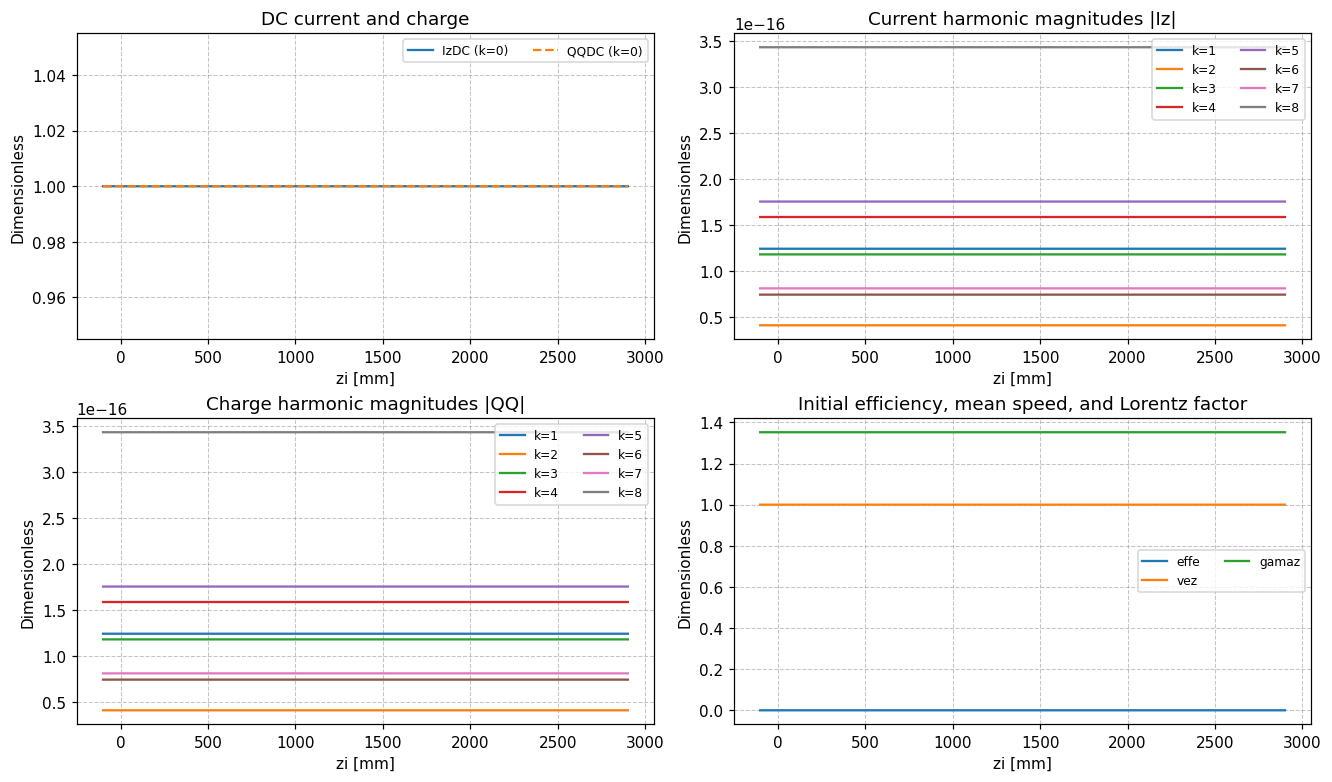

In [9]:
fig, axes = plt.subplots(2, 2, figsize=(12, 7), layout="constrained")
axes[0, 0].plot(grid.zi, beam_state.IzDC, label="IzDC (k=0)")
axes[0, 0].plot(grid.zi, beam_state.QQDC, "--", label="QQDC (k=0)")
axes[0, 0].set_title("DC current and charge")
for k in range(1, Ns + 1):
    axes[0, 1].plot(grid.zi, np.abs(beam_state.Iz[:, k - 1]), label=f"k={k}")
    axes[1, 0].plot(grid.zi, np.abs(beam_state.QQ[:, k - 1]), label=f"k={k}")
axes[0, 1].set_title("Current harmonic magnitudes |Iz|")
axes[1, 0].set_title("Charge harmonic magnitudes |QQ|")
for name in ("effe", "vez", "gamaz"):
    axes[1, 1].plot(grid.zi, getattr(beam_state, name), label=name)
axes[1, 1].set_title("Initial efficiency, mean speed, and Lorentz factor")
for ax in axes.flat:
    ax.set(xlabel="zi [mm]", ylabel="Dimensionless")
    ax.legend(ncol=2, fontsize=8)
plt.show()


## 6. Reconstruct the entrance waveform

With the code's extra factor \(i\), the current reconstruction is
\[
I_{\mathrm{normalized}}(\theta)
=IzDC+\operatorname{Im}\sum_{k=1}^{Ns}Iz_k e^{ik\theta}.
\]
Use the same expression with `QQDC, QQ` for charge.

The dots show the prescribed weights, with inactive samples set to zero. The curves retain only `Ns` harmonics; a partially active beam has sharp edges and therefore truncation ringing. This is a Fourier visualization, **not a beam-dynamics computation**.


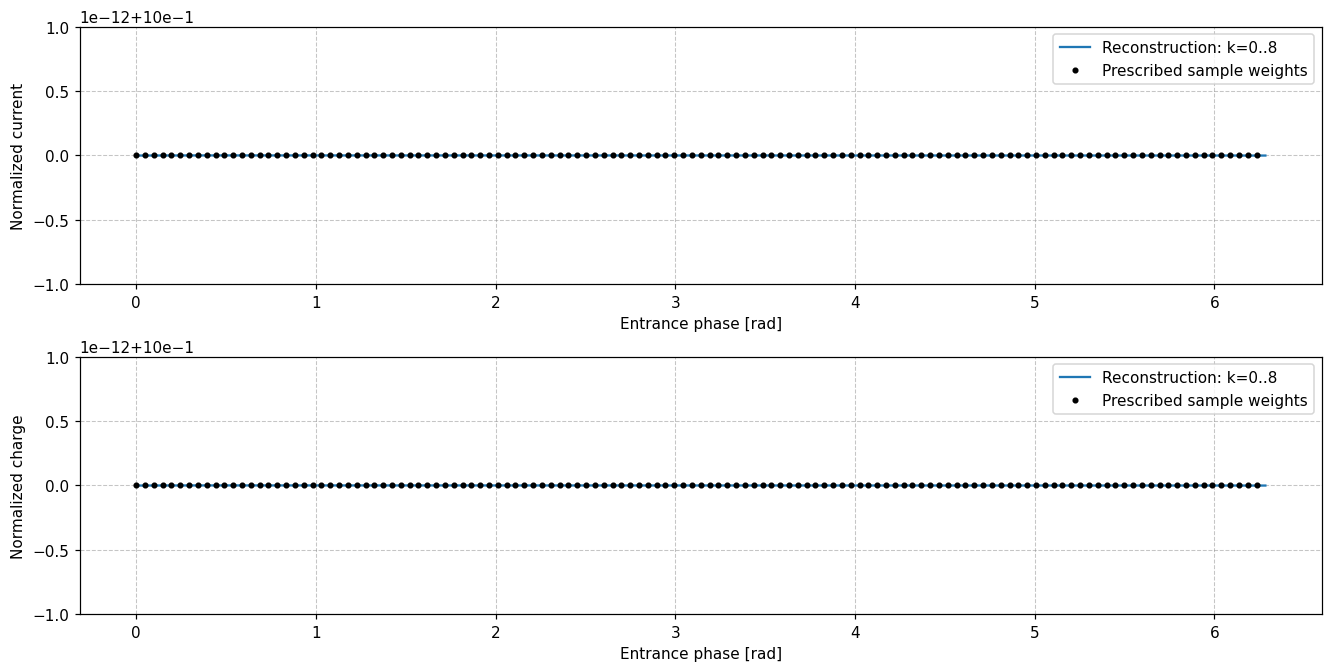

In [10]:
theta = np.linspace(beam.tn1.min(), beam.tn1.min() + 2.0 * np.pi, 600)
phase = np.exp(1.0j * np.outer(theta, np.arange(1, Ns + 1)))
current_samples = np.zeros(Nt)
current_samples[beam.Y0] = beam.Izt[beam.Y0] / reference.Iz0
charge_samples = current_samples * reference.vn1

fig, axes = plt.subplots(2, 1, figsize=(12, 6), layout="constrained")
for ax, dc, coefficients, samples, label in (
    (axes[0], beam_state.IzDC[0], beam_state.Iz[0], current_samples, "Normalized current"),
    (axes[1], beam_state.QQDC[0], beam_state.QQ[0], charge_samples, "Normalized charge"),
):
    waveform = dc + np.imag(phase @ coefficients)
    ax.plot(theta, waveform, label=f"Reconstruction: k=0..{Ns}")
    ax.plot(beam.tn1, samples, ".", color="black", label="Prescribed sample weights")
    ax.set(xlabel="Entrance phase [rad]", ylabel=label)
    ax.legend()
plt.show()


## 7. Basic Python consistency checks

Check dimensions, finiteness, longitudinally constant initialization, DC normalization, and initial efficiency/velocity. An independent FFT check is also possible for these presets because the entrance phases are equally spaced, with only a constant phase offset.

This checks the `2i` convention and the phase shift, including inactive samples as zeros. It does not replace the separate MATLAB comparison.


In [11]:
assert Nt >= 16 and 1 <= Ns < Nt / 2
for name, values in vars(beam_state).items():
    expected_shape = (len(grid.z), Ns) if name in ("Iz", "QQ") else (len(grid.z),)
    assert values.shape == expected_shape, name
    assert np.all(np.isfinite(values)), name
    np.testing.assert_allclose(values, np.broadcast_to(values[0], values.shape), rtol=1e-10, atol=1e-12)

np.testing.assert_allclose(beam_state.IzDC, 1.0, rtol=1e-10, atol=1e-12)
np.testing.assert_allclose(beam_state.QQDC, np.mean(charge_samples), rtol=1e-10, atol=1e-12)
np.testing.assert_array_equal(beam_state.effe, np.zeros(len(grid.z)))
np.testing.assert_array_equal(beam_state.vez, np.ones(len(grid.z)))
np.testing.assert_allclose(beam_state.gamaz, reference.gama, rtol=1e-10, atol=1e-12)

# FFT is an alternative calculation for equally spaced phase samples.
if np.allclose(beam.tn1, beam.tn1[0] + 2.0 * np.pi * np.arange(Nt) / Nt):
    phase_shift = np.exp(-1.0j * np.arange(1, Ns + 1) * beam.tn1[0])
    expected_Iz = 2.0j / Nt * np.fft.fft(current_samples)[1:Ns + 1] * phase_shift
    expected_QQ = 2.0j / Nt * np.fft.fft(charge_samples)[1:Ns + 1] * phase_shift
    np.testing.assert_allclose(beam_state.Iz[0], expected_Iz, rtol=1e-10, atol=1e-12)
    np.testing.assert_allclose(beam_state.QQ[0], expected_QQ, rtol=1e-10, atol=1e-12)

# Constant sample speed means current and charge have identical weights.
if np.allclose(reference.vn1[beam.Y0], 1.0, rtol=0.0, atol=1e-12):
    np.testing.assert_allclose(beam_state.QQ, beam_state.Iz, rtol=1e-10, atol=1e-12)
    np.testing.assert_allclose(beam_state.QQDC, beam_state.IzDC, rtol=1e-10, atol=1e-12)

print("PASS: Python beam-state initialization checks.")
print("The Python–MATLAB comparison is a separate step.")


PASS: Python beam-state initialization checks.
The Python–MATLAB comparison is a separate step.


## 8. Export for the independent MATLAB test

This cell overwrites only `inputs.mat` and `python_results.mat` in this test folder.

- Inputs are raw parameters, not initialized harmonics or reference/grid results. `Y0 + 1` is exported for MATLAB's one-based indexing; real integer inputs become doubles.
- Results contain all seven `BeamState` arrays, seven beam reference quantities, five coordinate quantities, and the case label and `Nt/Ns` metadata.
- Complex `Iz/QQ` values and their matrix shapes are preserved. DC is **not** inserted into their exported columns.
- One-dimensional arrays are saved as row vectors; the comparison allows orientation differences only for declared vectors.

Each folder holds one selected case. Rerun both languages after changing it; the case label alone cannot detect every input change.


In [12]:
inputs = {
    **vars(beam),
    **vars(cavities),
    **vars(tube),
    **vars(numerical),
    "factorregion": factorregion,
    "case_name": case_name,
    "c": c,
    "etom": etom,
    "mu01": mu01,
}
inputs["Y0"] = beam.Y0 + 1
for name, value in inputs.items():
    if np.asarray(value).dtype.kind in "iub":
        inputs[name] = np.asarray(value, dtype=float)

python_results = {
    **vars(reference),
    **vars(beam_state),
    "betae": grid.betae, "dz": grid.dz, "zi": grid.zi, "z": grid.z, "dt": grid.dt,
    "case_name": case_name, "Nt": Nt, "Ns": Ns,
}
savemat(test_directory / "inputs.mat", inputs, oned_as="row")
savemat(test_directory / "python_results.mat", python_results, oned_as="row")

print("Saved:", test_directory / "inputs.mat")
print("Saved:", test_directory / "python_results.mat")
print("Next step: run beam_state_test.mlx (or beam_state_test.m) in MATLAB.")


Saved: C:\Users\lsito\Desktop\PyKlyC\pyKlyC\test\3.beam_state_test\inputs.mat
Saved: C:\Users\lsito\Desktop\PyKlyC\pyKlyC\test\3.beam_state_test\python_results.mat
Next step: run beam_state_test.mlx (or beam_state_test.m) in MATLAB.
